# Notebook 01: Data Exploration, Keywords, and Claude Test

**Team:** Teenna Pachika and Johanna Garcia

**Project question:** What's driving negative Duolingo reviews, and do those complaints get better or worse after certain app updates?

This notebook covers:
1. Data exploration
2. Keyword analysis
3. Keyword-based complaint categories
4. A small Claude labeling test and our Phase 3 tool plan

In [34]:
# Importing libraries
import pandas as pd
import matplotlib.pyplot as plt

# Defining a function to load and prep the reviews
def load_reviews(path="../data/duolingo_reviews.csv"):
    """Load the reviews, turn the date column into real dates, and add a word count column."""
    df = pd.read_csv(path)
    df["at"] = pd.to_datetime(df["at"])
    df["content"] = df["content"].fillna("")
    df["n_words"] = df["content"].str.split().str.len()
    return df

# Defining a function to keep only negative reviews
def get_negative(df, max_stars=2):
    """Keep only the 1-2 star reviews."""
    return df[df["score"] <= max_stars].copy()

# Setting chart colors: red-orange = negative, gray = neutral, green = positive
NEG_COLOR = "#B5544C"
STAR_COLORS = ["#B5544C", "#B5544C", "#BFBFBF", "#7A9E7E", "#7A9E7E"]

# Loading the data
df = load_reviews()
neg = get_negative(df)

# Checking the counts
print("All reviews:", len(df))
print("Negative reviews (1-2 stars):", len(neg))

All reviews: 50000
Negative reviews (1-2 stars): 4147


## 1. Data Exploration

In [35]:
# Checking the size of the dataset
print("Rows and columns:", df.shape)

# Checking the column types
df.info()

# Checking for missing values
print("\nMissing values per column:")
print(df.isna().sum())

Rows and columns: (50000, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   reviewId              50000 non-null  object        
 1   content               50000 non-null  object        
 2   score                 50000 non-null  int64         
 3   thumbsUpCount         50000 non-null  int64         
 4   reviewCreatedVersion  45857 non-null  object        
 5   at                    50000 non-null  datetime64[ns]
 6   n_words               50000 non-null  int64         
dtypes: datetime64[ns](1), int64(3), object(3)
memory usage: 2.7+ MB

Missing values per column:
reviewId                   0
content                    0
score                      0
thumbsUpCount              0
reviewCreatedVersion    4143
at                         0
n_words                    0
dtype: int64


In [36]:
# Counting reviews with the exact same text
print("Duplicate reviews:", df.duplicated(subset="content").sum())

# Showing the 10 most common repeated reviews
print("\nMost common repeated reviews:")
print(df["content"].value_counts().head(10))

Duplicate reviews: 11787

Most common repeated reviews:
content
good         1565
nice          778
very good     451
nice app      264
good app      255
very nice     254
best          238
Good          184
I love it     180
good 👍        179
Name: count, dtype: int64


score
1     3049
2     1098
3     2322
4     6538
5    36993
Name: count, dtype: int64

% of reviews that are 1-2 stars: 8.3


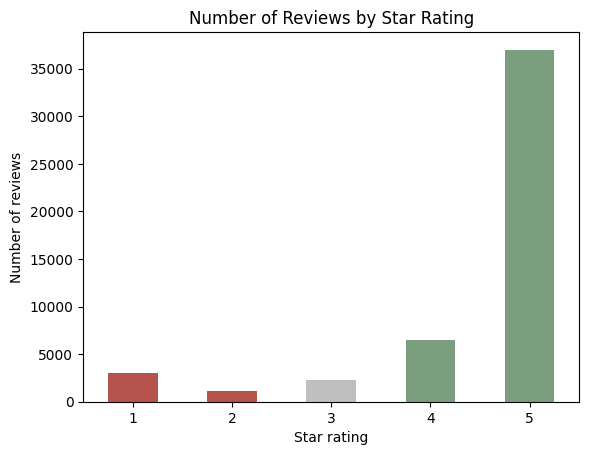

In [37]:
# Counting reviews for each star rating
star_counts = df["score"].value_counts().sort_index()
print(star_counts)
print("\n% of reviews that are 1-2 stars:", round(len(neg) / len(df) * 100, 1))

# Plotting the star rating distribution
star_counts.plot(kind="bar", color=STAR_COLORS)
plt.title("Number of Reviews by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Number of reviews")
plt.xticks(rotation=0)
plt.show()

count    50000.000000
mean        11.449580
std         16.322078
min          1.000000
25%          2.000000
50%          6.000000
75%         13.000000
max        115.000000
Name: n_words, dtype: float64

Median words by star rating:
score
1    17.0
2    19.0
3     9.0
4     6.0
5     5.0
Name: n_words, dtype: float64


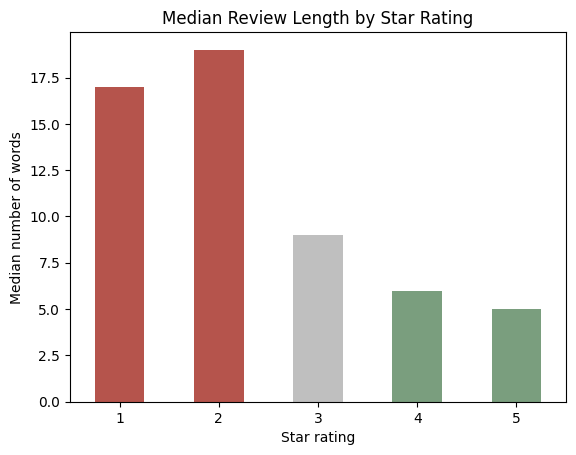

In [38]:
# Summarizing review length in words
print(df["n_words"].describe())

# Finding the median review length for each star rating
median_words = df.groupby("score")["n_words"].median()
print("\nMedian words by star rating:")
print(median_words)

# Plotting median review length by star rating
median_words.plot(kind="bar", color=STAR_COLORS)
plt.title("Median Review Length by Star Rating")
plt.xlabel("Star rating")
plt.ylabel("Median number of words")
plt.xticks(rotation=0)
plt.show()

In [39]:
# Showing 5 random negative reviews
pd.set_option("display.max_colwidth", None)
neg.sample(5, random_state=1)[["score", "content"]]

,score,content
38463,1,"Atrocious. spent 15 minutes repeating ""Yes, I, You, And"" and ran out of energy. useless for learning"
4368,1,it's not fair every country can use this app easily but WE ARE NOT because we are Iranian but we are not equal with government and this app shouldn't decide to make it worse for us when we need help to keep going
10063,2,"Discrimination against Iranian Citizens, Duo stopped giving services to Iranian Citizens like due language test, Duo dose not have learning Tibetan language but it has chinese. Duo dose not have listens for Kannada language. Duo listens for Hindi is very limited. needs a lot of improvement, otherwise I love this app."
11269,2,tough
38933,1,so bad


            all_reviews  negative  pct_negative
at                                             
2026-08-02         5198     393.0           7.6
2026-08-09         9206     719.0           7.8
2026-08-16         8744     640.0           7.3
2026-08-23         8166     622.0           7.6
2026-08-30         9079     902.0           9.9
2026-09-06         9606     871.0           9.1


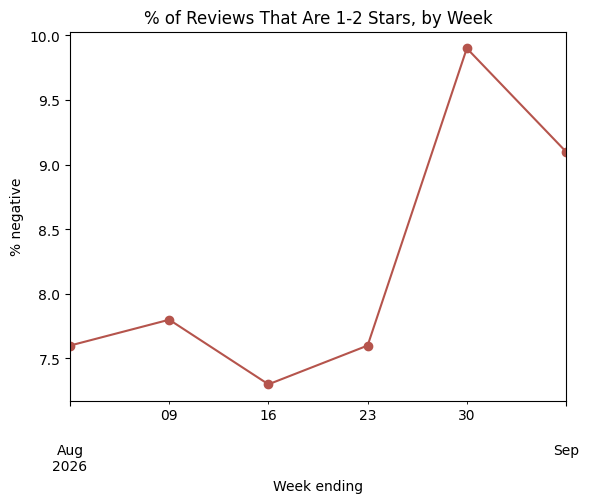

In [40]:
# Counting all reviews and negative reviews per week
weekly_all = df.set_index("at").resample("W").size()
weekly_neg = neg.set_index("at").resample("W").size()

# Calculating the % of reviews that are negative each week
weekly_pct = (weekly_neg / weekly_all * 100).round(1)
weekly_table = pd.DataFrame({"all_reviews": weekly_all, "negative": weekly_neg, "pct_negative": weekly_pct})
weekly_table = weekly_table[weekly_table["all_reviews"] > 100]   # dropping the near-empty last week
print(weekly_table)

# Plotting the % of negative reviews per week
weekly_table["pct_negative"].plot(marker="o", color=NEG_COLOR)
plt.title("% of Reviews That Are 1-2 Stars, by Week")
plt.xlabel("Week ending")
plt.ylabel("% negative")
plt.show()